
# Clase 7: Aprendizaje no supervisado

## Agrupamiento de datos de navegación robótica

### Objetivo

Implementar y analizar los algoritmos K-Means y DBSCAN para identificar patrones de agrupamiento en las lecturas de los 24 sensores del robot SCITOS-G5.

### Dataset

Se utiliza el conjunto de datos Wall-Following Robot Navigation, compuesto por 5456 registros y 24 variables correspondientes a sensores.

### Algoritmos implementados

- **K-Means:** agrupamiento por proximidad a centroides.
- **DBSCAN:** agrupamiento basado en densidad y detección de ruido.

Los algoritmos utilizan las características de los sensores sin emplear las etiquetas originales de navegación durante el entrenamiento.


In [1]:

import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.decomposition import PCA

# Rutas del proyecto
BASE_DIR = Path.cwd().resolve().parent

DATA_PATH = BASE_DIR / "data" / "raw" / "sensor_readings_24.data"
MODELS_DIR = BASE_DIR / "models"

# Cargar dataset
columnas = [f"sensor_{i}" for i in range(1, 25)] + ["clase"]

df = pd.read_csv(
    DATA_PATH,
    header=None,
    names=columnas
)

X = df.drop(columns=["clase"])

# Cargar modelos y escalador
scaler = joblib.load(MODELS_DIR / "unsupervised_scaler.pkl")
kmeans = joblib.load(MODELS_DIR / "kmeans.pkl")
dbscan = joblib.load(MODELS_DIR / "dbscan.pkl")

# Preparar datos
X_scaled = scaler.transform(X)

# Obtener etiquetas
etiquetas_kmeans = kmeans.predict(X_scaled)
etiquetas_dbscan = dbscan.labels_

print("Dataset cargado correctamente.")
print("Registros:", X_scaled.shape[0])
print("Sensores:", X_scaled.shape[1])
print("Clústeres K-Means:", len(set(etiquetas_kmeans)))
print("Clústeres DBSCAN:", len(set(etiquetas_dbscan) - {-1}))


Dataset cargado correctamente.
Registros: 5456
Sensores: 24
Clústeres K-Means: 4
Clústeres DBSCAN: 32


PCA aplicado correctamente.
Dimensiones originales: (5456, 24)
Dimensiones reducidas: (5456, 2)
Varianza explicada por PCA: 47.43 %


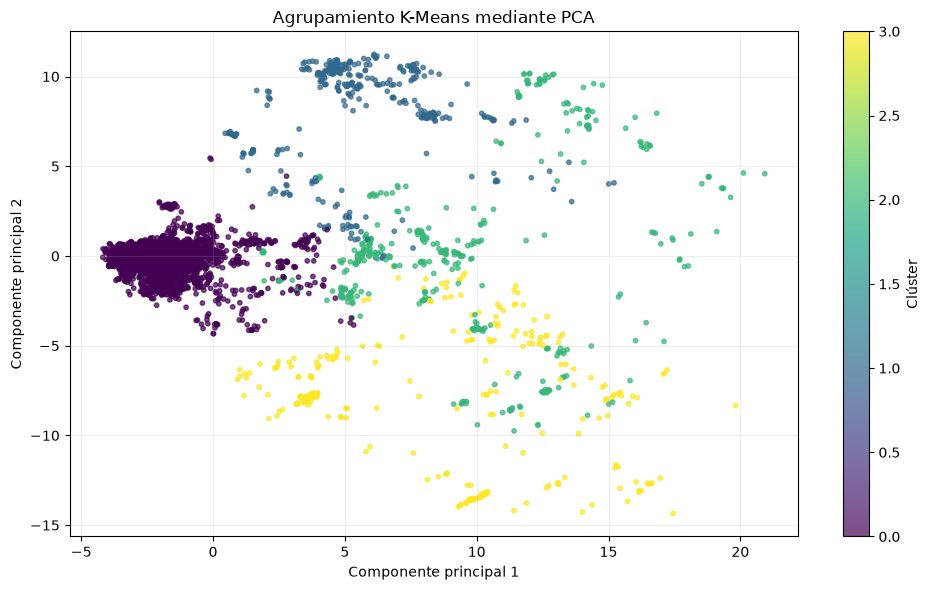

In [2]:

# Reducir las 24 variables a 2 componentes principales
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

print("PCA aplicado correctamente.")
print("Dimensiones originales:", X_scaled.shape)
print("Dimensiones reducidas:", X_pca.shape)

print(
    "Varianza explicada por PCA:",
    round(sum(pca.explained_variance_ratio_) * 100, 2),
    "%"
)

# Visualizar K-Means
plt.figure(figsize=(10, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=etiquetas_kmeans,
    cmap="viridis",
    s=10,
    alpha=0.7
)

plt.title("Agrupamiento K-Means mediante PCA")
plt.xlabel("Componente principal 1")
plt.ylabel("Componente principal 2")
plt.colorbar(label="Clúster")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


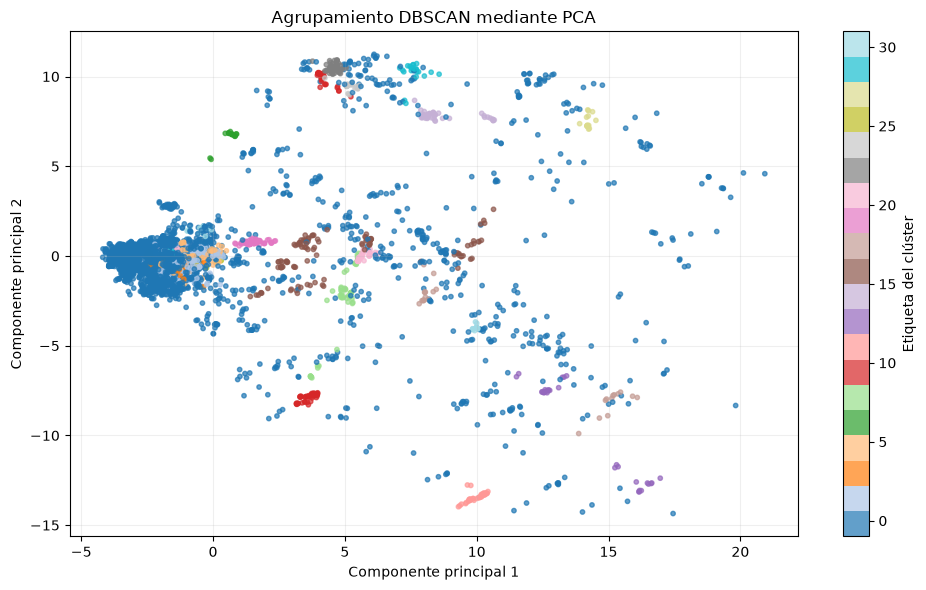

Clústeres DBSCAN: 32
Registros considerados ruido: 849


In [4]:

# Visualizar los agrupamientos de DBSCAN
plt.figure(figsize=(10, 6))

grafica = plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=etiquetas_dbscan,
    cmap="tab20",
    s=10,
    alpha=0.7
)

plt.title("Agrupamiento DBSCAN mediante PCA")
plt.xlabel("Componente principal 1")
plt.ylabel("Componente principal 2")

plt.colorbar(grafica, label="Etiqueta del clúster")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

print("Clústeres DBSCAN:", len(set(etiquetas_dbscan) - {-1}))
print("Registros considerados ruido:", np.sum(etiquetas_dbscan == -1))


## Análisis y conclusión de la Clase 7

En esta práctica se implementaron dos algoritmos de aprendizaje no supervisado, K-Means y DBSCAN, utilizando el conjunto de datos Wall-Following Robot Navigation, compuesto por 5456 registros y 24 variables correspondientes a sensores robóticos.

**K-Means** identificó cuatro clústeres y obtuvo un Silhouette Score de 0.4743, lo que sugiere una separación moderada entre los grupos encontrados.

**DBSCAN**, utilizando los parámetros `eps=3.0` y `min_samples=10`, identificó 32 clústeres y clasificó 849 registros como ruido, equivalentes aproximadamente al 15.56 % del conjunto de datos. Su Silhouette Score estimado fue de 0.1834, calculado sobre una muestra de los registros agrupados.

Mediante PCA se redujeron las 24 variables a dos componentes principales para visualizar los agrupamientos. Las gráficas permitieron observar una estructura más compacta en una parte de los datos agrupados por K-Means, mientras que DBSCAN identificó múltiples agrupaciones pequeñas y registros considerados ruido.

Los resultados sugieren que K-Means presenta una estructura de agrupamiento más favorable según la métrica obtenida. Sin embargo, las puntuaciones Silhouette no son directamente equivalentes debido a las diferencias en los registros utilizados para su cálculo.

**En conclusión**, ambos algoritmos permitieron identificar patrones sin utilizar las etiquetas originales de navegación. K-Means presentó resultados prometedores para segmentar las lecturas de los sensores, mientras que DBSCAN permitió explorar agrupaciones basadas en densidad y detectar posibles valores atípicos. Como trabajo futuro, se recomienda optimizar los parámetros y aplicar evaluaciones comparables para determinar la configuración más adecuada.